In [3]:
import re
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import srim

from pathlib import Path

In [4]:
# Define calculations in code
ion = srim.Ion('Si', energy=21.0e8) #eV

layer = srim.Layer({
    'Si': {
        'stoich': 0.5,
        'E_d': 35.0, # Displacement Energy
        'lattice': 0.0,
        'surface': 3.0
    },
    'C': {
        'stoich': 0.5,
        'E_d': 20.0, # Displacement Energy
        'lattice': 0.0,
        'surface': 3.0
    }
}, density=3.21, width=1.0e8)
target = srim.Target([layer])

SRIM_EXECUTABLE_DIRECTORY = os.path.abspath(r'C:\Program Files\SRIM-2013')
DATA_DIRECTORY = Path("../../../Desktop/nazar/examples/tmp_SiC").resolve()
NUM_IONS = 10
TRIM_SETTINGS = {
    'calculation': 2, # full cascade
    'collisions': 2,
    # 'angle_ions': 30
}

trim = srim.TRIM(target, ion, number_ions=NUM_IONS, **TRIM_SETTINGS)

In [5]:
trim.run(SRIM_EXECUTABLE_DIRECTORY)
os.makedirs(DATA_DIRECTORY, exist_ok=True)
srim.TRIM.copy_output_files(SRIM_EXECUTABLE_DIRECTORY, DATA_DIRECTORY)

In [19]:
int_regex = r'\d+'
float_regex = r'-?\d+\,\d*(?:E[+-]\d+)?' #/!\ ./, in function of the computer system (. for american, , for european)
element_regex = r'[A-Z][a-z]?'

ion_regex = 'Ion\s+Energy\s+Depth'
recoil_regex = r'Û\s+(' + r')\s+('.join([int_regex, int_regex, float_regex, float_regex, float_regex, float_regex, int_regex, int_regex]) + r')\s+Û'
cascade_regex = r'³\s*(' + r')\s*³\s*('.join([int_regex, float_regex, float_regex, float_regex, float_regex, float_regex, element_regex, float_regex]) + r')\s*³'

def format_recoil(index, recoil, atom, energy, x, y, z, vacancy, replacement):
    return int(index), int(recoil), int(atom), float(energy.replace(',', '.')), float(x.replace(',', '.')), float(y.replace(',', '.')), float(z.replace(',', '.')), int(vacancy), int(replacement)

def parse_ion_recoil(ion_block):
    return [format_recoil(m.start(), *m.groups()) for m in re.finditer(recoil_regex, ion_block)]

def format_cascade(index, ion, energy, x, y, z, stopping_energy, atom_hit, recoil_energy):
    return int(index), int(ion), float(energy.replace(',', '.')), float(x.replace(',', '.')), float(y.replace(',', '.')), float(z.replace(',', '.')), float(stopping_energy.replace(',', '.')), atom_hit, float(recoil_energy.replace(',', '.'))

def parse_ion_cascade(ion_block):
    return [format_cascade(m.start(), *m.groups()) for m in re.finditer(cascade_regex, ion_block)]

with open(DATA_DIRECTORY / 'COLLISON.txt', encoding='latin1') as f:
    collision = f.read()

# Tabular Representations

In [20]:
indicies = [(i, m.start()) for i, m in enumerate(re.finditer(ion_regex, collision), start=1)]
ion_indicies_df = pd.DataFrame(indicies,
                               columns=['ion_number', 'index']).set_index('ion_number')

recoils = parse_ion_recoil(collision)
recoils_df = pd.DataFrame(recoils, columns=['index',
                                            'recoil',
                                            'atom',
                                            'energy',
                                            'x',
                                            'y',
                                            'z',
                                            'vacancy',
                                            'replacement']).set_index('index')

cascade = parse_ion_cascade(collision)
cascade_df = pd.DataFrame(cascade, columns=['index',
                                            'ion',
                                            'energy',
                                            'x',
                                            'y',
                                            'z',
                                            'stopping_energy',
                                            'atom_hit',
                                            'recoil_energy']).set_index('index')

In [21]:
cascade_df.info()

<class 'pandas.DataFrame'>
Index: 18813 entries, 2069 to 16403825
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ion              18813 non-null  int64  
 1   energy           18813 non-null  float64
 2   x                18813 non-null  float64
 3   y                18813 non-null  float64
 4   z                18813 non-null  float64
 5   stopping_energy  18813 non-null  float64
 6   atom_hit         18813 non-null  str    
 7   recoil_energy    18813 non-null  float64
dtypes: float64(6), int64(1), str(1)
memory usage: 1.3 MB


In [22]:
cascade_df.sample(10)

,ion,energy,x,y,z,stopping_energy,atom_hit,recoil_energy
index,,,,,,,,
11773617,8,971800.000,18645000.0,30510.0,-31480.0,86.30,C,57.566
15646558,10,298300.000,23758000.0,1136000.0,439000.0,197.15,Si,923.470
3783113,3,852200.000,19877000.0,73210.0,60580.0,95.20,Si,304.120
5755055,4,105800.000,25074000.0,81900.0,91020.0,353.00,C,21.185
4264033,3,58320.000,25107000.0,84480.0,29250.0,442.04,Si,40.811
15533301,10,513400.000,22447000.0,914000.0,345600.0,137.03,Si,98.786
13181994,9,1734000.000,7211100.0,-33820.0,-47200.0,54.94,Si,35.957
11278226,7,8.113,25210000.0,18330.0,38740.0,16.87,C,56.535
9147078,6,112600.000,25019000.0,-27730.0,35130.0,343.11,Si,166.270


# Parse only Cascades for Demonstration

In [23]:
energies = []
dedx = []

for i in range(1, len(cascade)):
    c1 = cascade[i-1]
    c2 = cascade[i]
    if c1[1] != c2[1]:
        continue
    
    de = c1[2] - c2[2]
    dx = np.linalg.norm(np.array(c1[3:6]) - np.array(c2[3:6]))
    energies.append(c1[2])
    dedx.append(de/dx)

C:\Users\Sacha\AppData\Local\Temp\ipykernel_73768\99579490.py:13: RuntimeWarning: invalid value encountered in scalar divide
  dedx.append(de/dx)
C:\Users\Sacha\AppData\Local\Temp\ipykernel_73768\99579490.py:13: RuntimeWarning: divide by zero encountered in scalar divide
  dedx.append(de/dx)


Text(0.5, 1.0, 'Electronic Energy Loss Curve')

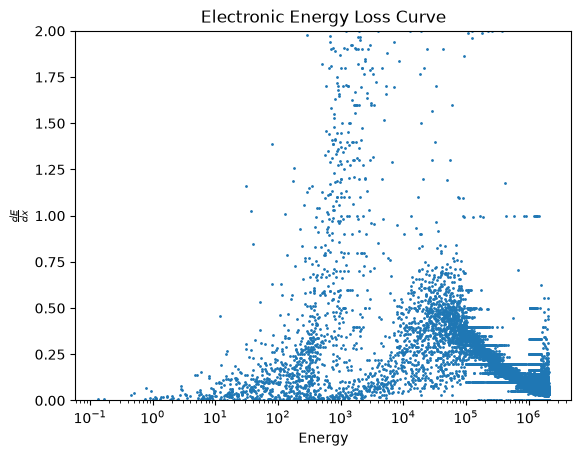

In [ ]:
fig, ax = plt.subplots()
ax.scatter(energies, dedx, s=1)
ax.set_ylim([0, 2])
ax.set_xlabel('Energy')
ax.set_ylabel(r'$\frac{dE}{dx}$')
ax.set_xscale('log')
ax.set_title('Electronic Energy Loss Curve')
plt.show()

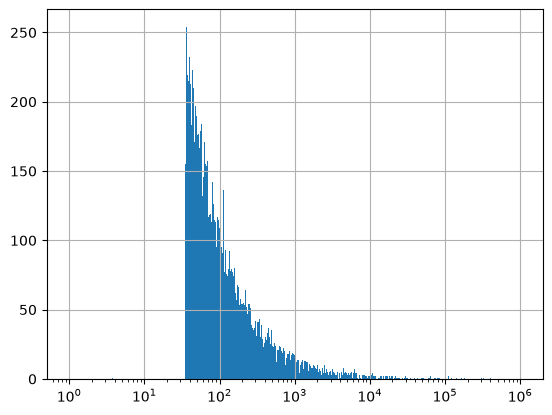

In [25]:
bins = 10**np.linspace(0, 6, 500)
ax = cascade_df[cascade_df['atom_hit'] == 'Si'].recoil_energy.hist(bins=bins)
ax.set_xscale('log')

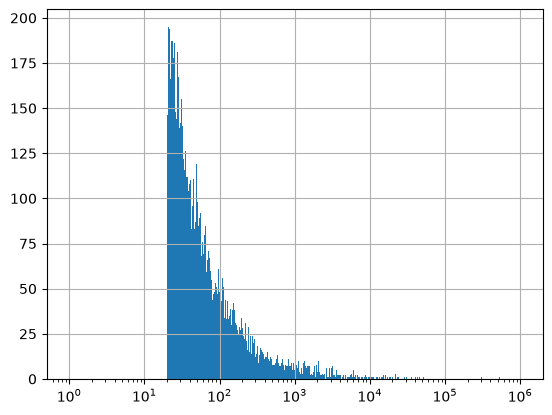

In [26]:
bins = 10**np.linspace(0, 6, 500)
ax = cascade_df[cascade_df['atom_hit'] == 'C'].recoil_energy.hist(bins=bins)
ax.set_xscale('log')

In [27]:
import numpy as np

def unit_vector(vector):
    """ Returns the unit vector of the vector.  """
    return vector / np.linalg.norm(vector)

def angle_between(v1, v2):
    """ Returns the angle in radians between vectors 'v1' and 'v2'::

            >>> angle_between((1, 0, 0), (0, 1, 0))
            1.5707963267948966
            >>> angle_between((1, 0, 0), (1, 0, 0))
            0.0
            >>> angle_between((1, 0, 0), (-1, 0, 0))
            3.141592653589793
    """
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    return np.arccos(np.clip(np.dot(v1_u, v2_u), -1.0, 1.0))

In [28]:
angles = []
energies = []

for i in range(1, len(cascade)-1):
    c1 = cascade[i-1]
    c2 = cascade[i]
    c3 = cascade[i+1]
    if (c1[1] != c2[1]) or (c2[1] != c3[1]):
        continue
    
    v1 = np.array(c1[3:6]) - np.array(c2[3:6])
    v2 = np.array(c2[3:6]) - np.array(c3[3:6])
    angles.append(angle_between(v1, v2))
    energies.append(c1[2])
    
angles = np.array(angles)

C:\Users\Sacha\AppData\Local\Temp\ipykernel_73768\3911922925.py:5: RuntimeWarning: invalid value encountered in divide
  return vector / np.linalg.norm(vector)


Text(0.5, 1.0, 'Electronic Energy Loss Curve')

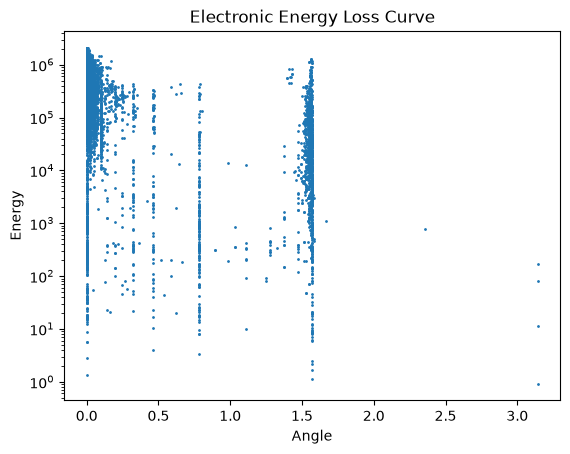

In [29]:
fig, ax = plt.subplots()
ax.scatter(angles, energies, s=1)
ax.set_xlabel('Angle')
ax.set_ylabel(r'Energy')
ax.set_yscale('log')
ax.set_title('Electronic Energy Loss Curve')

<Axes: >

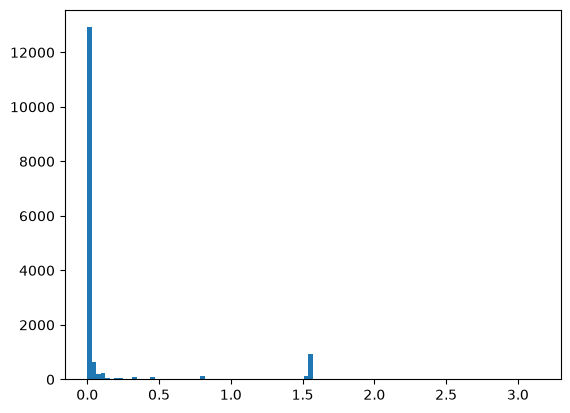

In [30]:
fig, ax = plt.subplots()
ax.hist(angles[~np.isnan(angles)], bins=100)
ax